# **Web Scraping & Data Handling Challenge**



### **Website:**
JustWatch -  https://www.justwatch.com/in/movies?release_year_from=2000


### **Description:**

JustWatch is a popular platform that allows users to search for movies and TV shows across multiple streaming services like Netflix, Amazon Prime, Hulu, etc. For this assignment, you will be required to scrape movie and TV show data from JustWatch using Selenium, Python, and BeautifulSoup. Extract data from HTML, not by directly calling their APIs. Then, perform data filtering and analysis using Pandas, and finally, save the results to a CSV file.

### **Tasks:**

**1. Web Scraping:**

Use BeautifulSoup to scrape the following data from JustWatch:

   **a. Movie Information:**

      - Movie title
      - Release year
      - Genre
      - IMDb rating
      - Streaming services available (Netflix, Amazon Prime, Hulu, etc.)
      - URL to the movie page on JustWatch

   **b. TV Show Information:**

      - TV show title
      - Release year
      - Genre
      - IMDb rating
      - Streaming services available (Netflix, Amazon Prime, Hulu, etc.)
      - URL to the TV show page on JustWatch

  **c. Scope:**

```
 ` - Scrape data for at least 50 movies and 50 TV shows.
   - You can choose the entry point (e.g., starting with popular movies,
     or a specific genre, etc.) to ensure a diverse dataset.`

```


**2. Data Filtering & Analysis:**

   After scraping the data, use Pandas to perform the following tasks:

   **a. Filter movies and TV shows based on specific criteria:**

   ```
      - Only include movies and TV shows released in the last 2 years (from the current date).
      - Only include movies and TV shows with an IMDb rating of 7 or higher.
```

   **b. Data Analysis:**

   ```
      - Calculate the average IMDb rating for the scraped movies and TV shows.
      - Identify the top 5 genres that have the highest number of available movies and TV shows.
      - Determine the streaming service with the most significant number of offerings.
      
   ```   

**3. Data Export:**

```
   - Dump the filtered and analysed data into a CSV file for further processing and reporting.

   - Keep the CSV file in your Drive Folder and Share the Drive link on the colab while keeping view access with anyone.
```

**Submission:**
```
- Submit a link to your Colab made for the assignment.

- The Colab should contain your Python script (.py format only) with clear
  comments explaining the scraping, filtering, and analysis process.

- Your Code shouldn't have any errors and should be executable at a one go.

- Before Conclusion, Keep your Dataset Drive Link in the Notebook.
```



**Note:**

1. Properly handle errors and exceptions during web scraping to ensure a robust script.

2. Make sure your code is well-structured, easy to understand, and follows Python best practices.

3. The assignment will be evaluated based on the correctness of the scraped data, accuracy of data filtering and analysis, and the overall quality of the Python code.








# **Start The Project**

## **Task 1:- Web Scrapping**

In [ ]:
#Installing all necessary labraries
!pip install bs4
!pip install requests
!pip install wordcloud

In [ ]:
#import all necessary labraries
import requests
from bs4 import BeautifulSoup
import re
import pandas as pd
import numpy as np

## **Scrapping Movies Data**

In [ ]:
# Specifying the URL from which movies related data will be fetched
url='https://www.justwatch.com/in?release_year_from=2000'
# Sending an HTTP GET request to the URL
page=requests.get(url)
# Parsing the HTML content using BeautifulSoup with the 'html.parser'
soup=BeautifulSoup(page.text,'html.parser')
# Printing the prettified HTML content
print(soup.prettify())

<!DOCTYPE html>
<meta charset="utf-8"/>
<meta content="width=device-width, initial-scale=1" name="viewport"/>
<title>
 403
</title>
403 Forbidden



## **Fetching Movie URL's**

In [ ]:
# Write Your Code here
data={"Movie_url":[],"Movie_title":[],"Release year":[],"Genre":[],"IMDb rating":[],"Runtime":[],"Age Rating":[],"Country":[],"Streaming services":[]}
movie_urls = []
start_url="https://www.justwatch.com"
# Find all the movie cards on the page
movie_cards = soup.find_all('div', {'class':'title-list-grid__item'})
# Extract URLs from the movie cards
for card in movie_cards:
    movie_url = card.find('a')['href']
    movie_urls.append(start_url+movie_url)
    data["Movie_url"].append(start_url+movie_url)
for element in movie_urls:
    print(element)
# Print the list of movie URLs
print(movie_urls)

[]


## **Scrapping Movie Title**

In [ ]:
movie_urls
# Iterate through each movie URL
for url in movie_urls:
     # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
        # Parse the HTML content using BeautifulSoup with the 'html.parser'
        soup = BeautifulSoup(response.text, 'html.parser')
        # Extract and print information from the page
        title_element = soup.find('h1')
        movie_title = title_element.text.strip() if title_element else "Title not found"
        #print(movie_urls) and insert to data
        print(f"Movie Title:{url}", movie_title,)
        data["Movie_title"].append(movie_title)
    else:
        print(f"Movie title", response.status_code)
        data["Movie_title"].append("")


Movie Title:https://www.justwatch.com/in/movie/12th-fail 12th Fail
Movie Title:https://www.justwatch.com/in/movie/animal-2022 Animal
Movie Title:https://www.justwatch.com/in/movie/tiger-3 Tiger 3
Movie Title:https://www.justwatch.com/in/movie/salaar Salaar
Movie Title:https://www.justwatch.com/in/movie/oppenheimer Oppenheimer
Movie Title:https://www.justwatch.com/in/movie/nani30 Hi Nanna
Movie Title:https://www.justwatch.com/in/movie/jawan Jawan
Movie Title:https://www.justwatch.com/in/movie/mission-impossible-7 Mission: Impossible - Dead Reckoning Part One
Movie Title:https://www.justwatch.com/in/movie/dunki Dunki
Movie Title:https://www.justwatch.com/in/movie/kho-gaye-hum-kahan Kho Gaye Hum Kahan
Movie Title:https://www.justwatch.com/in/movie/kaathal-the-core Kaathal – The Core
Movie Title:https://www.justwatch.com/in/movie/killers-of-the-flower-moon Killers of the Flower Moon
Movie Title:https://www.justwatch.com/in/movie/parking-2023 Parking
Movie Title:https://www.justwatch.com/in

## **Scrapping release Year**

In [ ]:
# Write Your Code here
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
        # Parse the HTML content using BeautifulSoup with the 'html.parser'
        soup = BeautifulSoup(response.text, 'html.parser')
        # Extract and print information from the page
        year_element = soup.find('span', class_='text-muted')
        movie_year = year_element.text.strip() if year_element else "Year not found"
        print(f"Release Year:", movie_year )
        data["Release year"].append(movie_year)
    else:
        print( response.status_code)

Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2018)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2001)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2024)
Release Year: (2023)
Release Year:

## **Scrapping Genres**

In [ ]:
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      # Find the <div> element with class 'detail-infos__value' under the 'Genres' heading
      genres_container = soup.find('h3', {'class': 'detail-infos__subheading'}, string='Genres')
      if genres_container:
          genre_element = genres_container.find_next('div', class_='detail-infos__value')
          # Extract and print the genre
          movie_genre = genre_element.text.strip() if genre_element else "Genre not found"
          print("Movie Genre:", movie_genre)
          data["Genre"].append(movie_genre)
      else:
          print("NaN")

Movie Genre: Drama
Movie Genre: Drama, Action & Adventure, Crime, Mystery & Thriller
Movie Genre: Mystery & Thriller, Action & Adventure
Movie Genre: Crime, Drama, Mystery & Thriller, Action & Adventure
Movie Genre: Drama, History
Movie Genre: Drama, Kids & Family, Romance
Movie Genre: Mystery & Thriller, Action & Adventure
Movie Genre: Mystery & Thriller, Action & Adventure
Movie Genre: Drama, Comedy
Movie Genre: Drama, Comedy
Movie Genre: Drama, Crime
Movie Genre: History, Crime, Drama, Romance, Western
Movie Genre: Mystery & Thriller, Drama
Movie Genre: Mystery & Thriller, Action & Adventure, Drama, Crime
Movie Genre: Drama
Movie Genre: Mystery & Thriller, Action & Adventure, Horror
Movie Genre: Mystery & Thriller, Action & Adventure, Crime, Drama
Movie Genre: Action & Adventure, Drama, Fantasy, Science-Fiction
Movie Genre: Drama, Comedy, Mystery & Thriller
Movie Genre: Action & Adventure, Comedy, Drama, Western
Movie Genre: Comedy, Fantasy
Movie Genre: Horror, Mystery & Thriller
Mo

## **Scrapping IMBD Rating**

In [ ]:
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      rating_container = soup.find('h3', class_='detail-infos__subheading', string='Rating')
      if rating_container:
          ratings = []
          # Iterate through each rating container within the parent <div>
          for rating_div in rating_container.find_next('div').find_all('div', class_='jw-scoring-listing__rating'):
              rating_span = rating_div.find('span')
              rating_text = rating_span.text.strip() if rating_span else "Rating not found"
              ratings.append(rating_text)
      if len(ratings) >= 2:
                # Print the second rating for the current movie
                print("Rating:", ratings[1])
                data["IMDb rating"].append(ratings[1])
    else:
                print("Second Rating: 0")

Rating: 9.2  (80k)
Rating: 6.8  (63k)
Rating: 6.5  (49k)
Rating: 6.7  (52k)
Rating: 8.4  (600k)
Rating: 8.3  (9k)
Rating: 7.0  (88k)
Rating: 7.7  (215k)
Rating: 7.6  (60k)
Rating: 7.7  (2k)
Rating: 7.7  (166k)
Rating: 8.2  (7k)
Rating: 7.5  (2k)
Rating: 7.2  (66k)
Rating: 6.7  (1k)
Rating: 7.2  (54k)
Rating: 5.6  (88k)
Rating: 7.1  (123k)
Rating: 8.1  (7k)
Rating: 6.9  (465k)
Rating: 7.1  (122k)
Rating: 8.3  (5k)
Rating: 7.6  (2k)
Rating: 6.8  (115k)
Rating: 8.0
Rating: 7.6  (2k)
Rating: 6.3  (29k)
Rating: 8.2  (8k)
Rating: 6.8  (512k)
Rating: 7.8  (39k)
Rating: 5.2  (21k)
Rating: 6.7  (40k)
Rating: 6.5  (8k)
Rating: 7.6  (844k)
Rating: 3.6  (5k)
Rating: 8.4  (30k)
Rating: 6.0  (30k)
Rating: 8.1  (3k)
Rating: 6.5  (160k)
Rating: 7.9  (50k)
Rating: 6.5  (89k)
Rating: 5.9  (154k)
Rating: 8.4  (1k)
Rating: 8.8  (11k)
Rating: 5.7  (72k)
Rating: 5.4  (13k)
Rating: 8.3  (147k)
Rating: 8.3  (37k)
Rating: 8.0  (7k)
Rating: 5.8  (110k)
Rating: 7.6  (85k)
Rating: 5.3
Rating: 5.3
Rating: 3.3  (96

## **Scrapping Runtime/Duration**

In [ ]:
# Write Your Code here
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      # Find the <div> element with class 'detail-infos__value' under the 'Genres' heading
      Duration= soup.find('h3', {'class': 'detail-infos__subheading'}, string='Runtime')
      if Duration:
          Duration_element = Duration.find_next('div', class_='detail-infos__value')
          # Extract and print the genre
          movie_duration = Duration_element.text.strip() if Duration_element else "Genre not found"
          print("Runtime:", movie_duration)
          data["Runtime"].append(movie_duration)
      else:
          print("NaN")
          data["Runtime"].append(0)

Runtime: 2h 26min
Runtime: 3h 21min
Runtime: 2h 36min
Runtime: 2h 55min
Runtime: 3h 1min
Runtime: 2h 35min
Runtime: 2h 49min
Runtime: 2h 44min
Runtime: 2h 40min
Runtime: 2h 15min
Runtime: 1h 52min
Runtime: 3h 26min
Runtime: 2h 7min
Runtime: 2h 33min
Runtime: 2h 18min
Runtime: 2h 25min
Runtime: 2h 43min
Runtime: 2h 13min
Runtime: 2h 11min
Runtime: 2h 52min
Runtime: 1h 54min
Runtime: 1h 34min
Runtime: 2h 20min
Runtime: 1h 39min
Runtime: 2h 14min
Runtime: 1h 46min
Runtime: 2h 24min
Runtime: 1h 59min
Runtime: 2h 30min
Runtime: 2h 23min
Runtime: 2h 32min
Runtime: 2h 48min
Runtime: 1h 35min
Runtime: 2h 48min
Runtime: 2h 20min
Runtime: 2h 32min
Runtime: 2h 26min
Runtime: 2h 21min
Runtime: 2h 4min
Runtime: 2h 0min
Runtime: 2h 21min
Runtime: 2h 24min
Runtime: 2h 38min
Runtime: 2h 26min
Runtime: 2h 28min
Runtime: 2h 39min
Runtime: 1h 45min
Runtime: 1h 46min
Runtime: 2h 46min
Runtime: 2h 5min
Runtime: 2h 13min
Runtime: 2h 22min
Runtime: 2h 55min
Runtime: 2h 8min
Runtime: 2h 13min
Runtime: 1h 54mi

## **Scrapping Age Rating**

In [ ]:
# Write Your Code here
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      age_rating_heading = soup.find('h3', class_='detail-infos__subheading', string='Age rating')
# If the heading is found, extract the next sibling <div> element's text content
      if age_rating_heading:
          age_rating_value = age_rating_heading.find_next('div', class_='detail-infos__value')
          age_rating = age_rating_value.text.strip() if age_rating_value else "Age rating not found"
          print("Age Rating:", age_rating)
          data["Age Rating"].append(age_rating)
      else:
          print("NaN")
          data["Age Rating"].append("NaN")

NaN
Age Rating: A
NaN
Age Rating: A
Age Rating: UA
Age Rating: U
Age Rating: UA
NaN
NaN
NaN
Age Rating: UA
Age Rating: A
Age Rating: UA
NaN
Age Rating: A
NaN
Age Rating: UA
NaN
NaN
Age Rating: UA
Age Rating: UA
NaN
Age Rating: UA
NaN
NaN
Age Rating: UA
NaN
Age Rating: A
Age Rating: UA
Age Rating: UA
NaN
Age Rating: UA
NaN
NaN
Age Rating: UA
Age Rating: U
Age Rating: UA
NaN
NaN
Age Rating: U
NaN
NaN
NaN
NaN
Age Rating: UA
Age Rating: UA
NaN
NaN
Age Rating: UA
NaN
Age Rating: A
Age Rating: UA
Age Rating: UA
Age Rating: A
NaN
NaN
NaN
NaN
Age Rating: U
NaN
NaN
Age Rating: UA
NaN
NaN
NaN
Age Rating: A
NaN
Age Rating: A
NaN
NaN
Age Rating: UA
Age Rating: UA
Age Rating: UA
Age Rating: UA
NaN
Age Rating: A
Age Rating: UA
Age Rating: A
NaN
NaN
Age Rating: UA
Age Rating: UA
Age Rating: UA
Age Rating: A
Age Rating: UA
Age Rating: UA
NaN
Age Rating: UA
Age Rating: UA
Age Rating: A
Age Rating: UA
Age Rating: A
Age Rating: A
Age Rating: UA
Age Rating: UA
Age Rating: A
NaN
Age Rating: UA
NaN
Age Rati

## **Fetching Production Countries Details**

In [ ]:
# Write Your Code here
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.content,  'html.parser')
      production_country_heading = soup.find('h3', class_='detail-infos__subheading', text=lambda text: text and 'Production country' in text)
      # If the heading is found, extract the next sibling <div> element's text content
      if production_country_heading:
          production_country_value = production_country_heading.find_next('div', class_='detail-infos__value')
          production_countries = production_country_value.text.strip() if production_country_value else "Production country not found"
          print("Production Countries:", production_countries)
          data["Country"].append(production_countries)
      else:
          print("Production Country information not found.")


<ipython-input-321-1cc82e8ee9ad>:9: DeprecationWarning: The 'text' argument to find()-type methods is deprecated. Use 'string' instead.
  production_country_heading = soup.find('h3', class_='detail-infos__subheading', text=lambda text: text and 'Production country' in text)


Production Countries: India
Production Countries: United States, India
Production Countries: India
Production Countries: India
Production Countries: United Kingdom, United States
Production Countries: India
Production Countries: India
Production Countries: United States
Production Countries: India
Production Countries: India
Production Countries: India
Production Countries: United States
Production Countries: India
Production Countries: India
Production Countries: India
Production Countries: India
Production Countries: India
Production Countries: United States
Production Countries: United Kingdom, United States
Production Countries: India
Production Countries: United States, United Kingdom
Production Countries: Australia, United Kingdom
Production Countries: India
Production Countries: India
Production Countries: Canada, United States
Production Countries: South Korea, United States
Production Countries: India
Production Countries: United States
Production Countries: India
Production C

## **Fetching Streaming Service Details**

In [ ]:
movie_urls
# Iterate through each movie URL
for url in movie_urls:
    # Make a request to the movie URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.content,  'html.parser')
      img_tag = soup.find('img', class_='offer__icon')

    if img_tag:
        # Check if the 'alt' attribute is present
        alt_attribute = img_tag.get('alt')

        if alt_attribute:
            netflix_text = alt_attribute.strip()
            data["Streaming services"].append(netflix_text)
            print(netflix_text)
        else:
            print("Alt attribute not found.")
            data["Streaming services"].append("NaN")
    else:
        print("Image tag not found.")
        data["Streaming services"].append("NaN")
else:
    print("Error fetching the URL. Status code:", response.status_code)

Hotstar
Bookmyshow
Amazon Prime Video
Bookmyshow
Apple TV
Netflix
Netflix
Apple TV
Bookmyshow
Netflix
Amazon Prime Video
Apple TV Plus
Hotstar
Sony Liv
Image tag not found.
Hotstar
Netflix
Netflix
Image tag not found.
Netflix
Apple TV
Apple TV
Hotstar
Netflix
Apple TV
Lionsgate Play
Amazon Prime Video
Apple TV Plus
Bookmyshow
Apple TV
Image tag not found.
Zee5
Netflix
Amazon Prime Video
Image tag not found.
Apple TV
Bookmyshow
Image tag not found.
Bookmyshow
aha
Netflix
Netflix
Amazon Video
Apple TV
Image tag not found.
Image tag not found.
Bookmyshow
Netflix
Amazon Prime Video
Image tag not found.
Voot
Apple TV
Amazon Prime Video
Amazon Prime Video
Image tag not found.
Netflix
Amazon Prime Video
Netflix
Amazon Prime Video
Netflix
Apple TV
Amazon Prime Video
Netflix
Zee5
Hotstar
Amazon Prime Video
Image tag not found.
Lionsgate Play
Zee5
Amazon Prime Video
Apple TV
Amazon Prime Video
Hotstar
Apple TV
Bookmyshow
Netflix
Bookmyshow
Apple TV
Lionsgate Play
Amazon Prime Video
Apple TV
Voot

## **Now Creating Movies DataFrame**

In [ ]:
max_length = max(len(value) for value in data.values())

# Pad shorter lists with a placeholder value (None in this case)
for key, value in data.items():
    if len(value) < max_length:
        data[key] = value + [None] * (max_length - len(value))

# Create the DataFrame
df_movie = pd.DataFrame.from_dict(data)
df_movie



,Movie_url,Movie_title,Release year,Genre,IMDb rating,Runtime,Age Rating,Country,Streaming services
0,https://www.justwatch.com/in/movie/12th-fail,12th Fail,(2023),Drama,9.2 (80k),2h 26min,NaN,India,Hotstar
1,https://www.justwatch.com/in/movie/animal-2022,Animal,(2023),"Drama, Action & Adventure, Crime, Mystery & Th...",6.8 (63k),3h 21min,A,"United States, India",Bookmyshow
2,https://www.justwatch.com/in/movie/tiger-3,Tiger 3,(2023),"Mystery & Thriller, Action & Adventure",6.5 (49k),2h 36min,NaN,India,Amazon Prime Video
3,https://www.justwatch.com/in/movie/salaar,Salaar,(2023),"Crime, Drama, Mystery & Thriller, Action & Adv...",6.7 (52k),2h 55min,A,India,Bookmyshow
4,https://www.justwatch.com/in/movie/oppenheimer,Oppenheimer,(2023),"Drama, History",8.4 (600k),3h 1min,UA,"United Kingdom, United States",Apple TV
...,...,...,...,...,...,...,...,...,...
95,https://www.justwatch.com/in/movie/the-equaliz...,The Equalizer 3,(2023),"Mystery & Thriller, Crime, Action & Adventure",7.7 (4k),1h 49min,A,"United States, Italy",Apple TV
96,https://www.justwatch.com/in/movie/role-play-2023,Role Play,(2023),"Comedy, Romance, Action & Adventure",7.6 (508k),1h 41min,NaN,"United States, France, Germany",Amazon Prime Video
97,https://www.justwatch.com/in/movie/dont-breathe-2,Don't Breathe 2,(2021),"Horror, Mystery & Thriller, Action & Adventure...",None,1h 38min,UA,United States,Apple TV
98,https://www.justwatch.com/in/movie/800,800,(2023),"Sport, Drama",None,2h 38min,NaN,India,Amazon Prime Video


In [ ]:
df_movie.columns

Index(['Movie_url', 'Movie_title', 'Release year', 'Genre', 'IMDb rating',
       'Runtime', 'Age Rating', 'Country', 'Streaming services'],
      dtype='object')

## **Scraping TV  Show Data**

In [ ]:
# Specifying the URL from which tv show related data will be fetched
tv_url='https://www.justwatch.com/in/tv-shows?release_year_from=2014'
# Sending an HTTP GET request to the URL
page=requests.get(tv_url)
# Parsing the HTML content using BeautifulSoup with the 'html.parser'
soup=BeautifulSoup(page.text,'html.parser')
# Printing the prettified HTML content
print(soup.prettify())

<!DOCTYPE html>
<html data-vue-meta="%7B%22dir%22:%7B%22ssr%22:%22ltr%22%7D,%22lang%22:%7B%22ssr%22:%22en%22%7D%7D" data-vue-meta-server-rendered="" dir="ltr" lang="en">
 <head>
  <meta charset="utf-8"/>
  <meta content="IE=edge" http-equiv="X-UA-Compatible"/>
  <meta charset="utf-8" data-vue-meta="ssr"/>
  <meta content="IE=edge" data-vue-meta="ssr" httpequiv="X-UA-Compatible"/>
  <meta content="viewport-fit=cover, width=device-width, initial-scale=1.0, minimum-scale=1.0, maximum-scale=1.0, user-scalable=no" data-vue-meta="ssr" name="viewport"/>
  <meta content="JustWatch" data-vue-meta="ssr" property="og:site_name"/>
  <meta content="794243977319785" data-vue-meta="ssr" property="fb:app_id"/>
  <meta content="/appassets/img/JustWatch_logo_with_claim.png" data-vmid="og:image" data-vue-meta="ssr" property="og:image"/>
  <meta content="606" data-vmid="og:image:width" data-vue-meta="ssr" property="og:image:width"/>
  <meta content="302" data-vmid="og:image:height" data-vue-meta="ssr" pro

## **Fetching Tv shows Url details**

In [ ]:
# Write Your Code here
data_tv={"Tv_url":[],"Tv_title":[],"Release year":[],"Genre":[],"IMDb rating":[],"Runtime":[],"Age Rating":[],"Country":[],"Streaming services":[]}
tv_urls = []
start_url="https://www.justwatch.com"
# Find all the tv cards on the page
tv_cards = soup.find_all('div', {'class':'title-list-grid__item'})
# Extract URLs from the tv cards
for card in tv_cards:
    tv_url = card.find('a')['href']
    tv_urls.append(start_url+tv_url)
    data_tv["Tv_url"].append(start_url+tv_url)
for element in tv_urls:
    print(element)
print(tv_urls)

https://www.justwatch.com/in/tv-show/jack-reacher
https://www.justwatch.com/in/tv-show/berlin
https://www.justwatch.com/in/tv-show/what-if-2021
https://www.justwatch.com/in/tv-show/the-freelancer
https://www.justwatch.com/in/tv-show/mirzapur
https://www.justwatch.com/in/tv-show/jujutsu-kaisen
https://www.justwatch.com/in/tv-show/farzi
https://www.justwatch.com/in/tv-show/monarch-legacy-of-monsters
https://www.justwatch.com/in/tv-show/true-detective
https://www.justwatch.com/in/tv-show/the-last-of-us
https://www.justwatch.com/in/tv-show/the-railway-men-the-untold-story-of-bhopal-1984
https://www.justwatch.com/in/tv-show/my-demon
https://www.justwatch.com/in/tv-show/solo-leveling-2024
https://www.justwatch.com/in/tv-show/flames
https://www.justwatch.com/in/tv-show/aashram
https://www.justwatch.com/in/tv-show/asur
https://www.justwatch.com/in/tv-show/the-legend-of-hanuman
https://www.justwatch.com/in/tv-show/fool-me-once
https://www.justwatch.com/in/tv-show/killer-soup
https://www.justwat

## **Fetching Tv Show Title details**

In [ ]:
# Write Your Code here
tv_urls
# Iterate through each tv URL
for url in tv_urls:
     # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
        # Parse the HTML content using BeautifulSoup with the 'html.parser'
        soup = BeautifulSoup(response.text, 'html.parser')
        # Extract and print information from the page
        title_element = soup.find('h1')
        tv_title = title_element.text.strip() if title_element else "Title not found"
        print(f"Movie Title:{url}", tv_title,)
        data_tv["Tv_title"].append(tv_title)
    else:
        print(f"Movie Name", response.status_code)


Movie Title:https://www.justwatch.com/in/tv-show/jack-reacher Reacher
Movie Title:https://www.justwatch.com/in/tv-show/berlin Berlin
Movie Title:https://www.justwatch.com/in/tv-show/what-if-2021 What If...?
Movie Title:https://www.justwatch.com/in/tv-show/the-freelancer The Freelancer
Movie Title:https://www.justwatch.com/in/tv-show/mirzapur Mirzapur
Movie Title:https://www.justwatch.com/in/tv-show/jujutsu-kaisen Jujutsu Kaisen
Movie Title:https://www.justwatch.com/in/tv-show/farzi Farzi
Movie Title:https://www.justwatch.com/in/tv-show/monarch-legacy-of-monsters Monarch: Legacy of Monsters
Movie Title:https://www.justwatch.com/in/tv-show/true-detective True Detective
Movie Title:https://www.justwatch.com/in/tv-show/the-last-of-us The Last of Us
Movie Title:https://www.justwatch.com/in/tv-show/the-railway-men-the-untold-story-of-bhopal-1984 The Railway Men - The Untold Story of Bhopal 1984
Movie Title:https://www.justwatch.com/in/tv-show/my-demon My Demon
Movie Title:https://www.justwat

## **Fetching Release Year**

In [ ]:
# Write Your Code here
tv_urls
# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
        # Parse the HTML content using BeautifulSoup with the 'html.parser'
        soup = BeautifulSoup(response.text, 'html.parser')
        # Extract and print information from the page
        year_element = soup.find('span', class_='text-muted')
        tv_year = year_element.text.strip() if year_element else "Year not found"
        print(f"Release Year:", tv_year )
        data_tv["Release year"].append(tv_year)
    else:
        print( response.status_code)

Release Year: (2022)
Release Year: (2023)
Release Year: (2021)
Release Year: (2023)
Release Year: (2018)
Release Year: (2020)
Release Year: (2023)
Release Year: (2023)
Release Year: (2014)
Release Year: (2023)
Release Year: (2023)
Release Year: (2023)
Release Year: (2024)
Release Year: (2018)
Release Year: (2020)
Release Year: (2020)
Release Year: (2021)
Release Year: (2024)
Release Year: (2024)
Release Year: (2022)
Release Year: (2023)
Release Year: (2017)
Release Year: (2023)
Release Year: (2020)
Release Year: (2023)
Release Year: (2014)
Release Year: (2023)
Release Year: (2018)
Release Year: (2016)
Release Year: (2020)
Release Year: (2021)
Release Year: (2019)
Release Year: (2021)
Release Year: (2023)
Release Year: (2021)
Release Year: (2018)
Release Year: (2018)
Release Year: (2023)
Release Year: (2024)
Release Year: (2021)
Release Year: (2016)
Release Year: (2023)
Release Year: (2023)
Release Year: (2019)
Release Year: (2020)
Release Year: (2023)
Release Year: (2019)
Release Year:

## **Fetching TV Show Genre Details**

In [ ]:
# Write Your Code here
tv_urls
# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      # Find the <div> element with class 'detail-infos__value' under the 'Genres' heading
      genres_container = soup.find('h3', {'class': 'detail-infos__subheading'}, string='Genres')
      if genres_container:
          genre_element = genres_container.find_next('div', class_='detail-infos__value')
          # Extract and print the genre
          tv_genre = genre_element.text.strip() if genre_element else "Genre not found"
          print("Movie Genre:",tv_genre)
          data_tv["Genre"].append(tv_genre)
      else:
          print("NaN")

Movie Genre: Crime, Drama, Mystery & Thriller, Action & Adventure
Movie Genre: Action & Adventure, Crime, Drama, Mystery & Thriller
Movie Genre: Action & Adventure, Science-Fiction, Animation
Movie Genre: Mystery & Thriller, Action & Adventure, Drama
Movie Genre: Crime, Action & Adventure, Mystery & Thriller, Drama
Movie Genre: Action & Adventure, Fantasy, Mystery & Thriller, Animation, Science-Fiction
Movie Genre: Drama, Crime, Mystery & Thriller
Movie Genre: Drama, Science-Fiction, Action & Adventure
Movie Genre: Drama, Mystery & Thriller, Crime
Movie Genre: Drama, Science-Fiction, Mystery & Thriller, Action & Adventure, Horror
Movie Genre: Drama, Mystery & Thriller, History
Movie Genre: Science-Fiction, Comedy, Drama, Fantasy, Romance
Movie Genre: Action & Adventure, Fantasy, Animation, Science-Fiction
Movie Genre: Drama, Comedy, Romance, Made in Europe
Movie Genre: Crime, Drama, Mystery & Thriller
Movie Genre: Mystery & Thriller, Crime, Drama
Movie Genre: Animation, Action & Advent

## **Fetching IMDB Rating Details**

In [ ]:
# Write Your Code here
tv_urls

# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      rating_container = soup.find('h3', class_='detail-infos__subheading', string='Rating')
      if rating_container:
          tv_ratings = []
          # Iterate through each rating container within the parent <div>
          for rating_div in rating_container.find_next('div').find_all('div', class_='jw-scoring-listing__rating'):
              rating_span = rating_div.find('span')
              tv_rating_text = rating_span.text.strip() if rating_span else "Rating not found"
              tv_ratings.append(tv_rating_text)
      if len(tv_ratings) >= 2:
                print("Rating:", tv_ratings[1])
                data_tv["IMDb rating"].append(tv_ratings[1])
    else:
                print("Second Rating: 0")
                print("---")

Rating: 8.1  (181k)
Rating: 7.1  (18k)
Rating: 7.5  (88k)
Rating: 8.2  (5k)
Rating: 8.5  (80k)
Rating: 8.6  (102k)
Rating: 8.4  (42k)
Rating: 7.0  (25k)
Rating: 8.9  (623k)
Rating: 8.8  (487k)
Rating: 8.5  (18k)
Rating: 8.0  (3k)
Rating: 8.5  (3k)
Rating: 8.9  (32k)
Rating: 7.4  (32k)
Rating: 8.5  (64k)
Rating: 9.2  (11k)
Rating: 6.9  (27k)
Rating: 6.3  (1k)
Rating: 8.6  (182k)
Rating: 8.8  (4k)
Rating: 8.2  (521k)
Rating: 7.4  (6k)
Rating: 8.9  (82k)
Rating: 7.8  (3k)
Rating: 8.9  (406k)
Rating: 7.4  (16k)
Rating: 3.4  (2k)
Rating: 8.5
Rating: 7.2  (2k)
Rating: 7.9  (8k)
Rating: 8.7  (96k)
Rating: 8.2  (401k)
Rating: 8.1  (47k)
Rating: 7.8  (81k)
Rating: 8.9  (254k)
Rating: 8.7  (203k)
Rating: 8.0  (6k)
Rating: 8.3
Rating: 7.2  (2k)
Rating: 8.1  (349k)
Rating: 8.4  (136k)
Rating: 8.0  (8k)
Rating: 7.9
Rating: 9.3  (150k)
Rating: 7.1  (18k)
Rating: 9.1  (20k)
Rating: 9.2  (309k)
Rating: 7.7  (9k)
Rating: 8.1  (347k)
Rating: 6.1  (18k)
Rating: 7.9  (13k)
Rating: 8.0  (62k)
Rating: 8.3  

## **Fetching Age Rating Details**

In [ ]:
tv_urls
# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      age_rating_heading = soup.find('h3', class_='detail-infos__subheading', string='Age rating')
# If the heading is found, extract the next sibling <div> element's text content
      if age_rating_heading:
          age_rating_value = age_rating_heading.find_next('div', class_='detail-infos__value')
          tv_age_rating = age_rating_value.text.strip() if age_rating_value else "Age rating not found"
          print("Age Rating:",tv_age_rating)
          data_tv["Age Rating"].append(tv_age_rating)
      else:
          print("NaN")
          data_tv["Age Rating"].append("NaN")

Age Rating: A
NaN
NaN
NaN
NaN
NaN
NaN
NaN
Age Rating: U
Age Rating: A
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
Age Rating: A
NaN
NaN
Age Rating: A
NaN
NaN
Age Rating: UA
NaN
NaN
NaN
NaN
Age Rating: A
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
NaN
Age Rating: A
Age Rating: A
NaN
NaN
Age Rating: A
Age Rating: A
Age Rating: A
NaN
Age Rating: A
NaN
NaN
NaN
Age Rating: A
NaN
NaN
NaN
NaN
Age Rating: A
Age Rating: A
Age Rating: A
NaN
NaN
Age Rating: A
NaN
Age Rating: A
NaN
NaN
NaN
Age Rating: A
NaN
NaN
NaN
Age Rating: A
Age Rating: U
NaN
Age Rating: U
NaN
NaN
NaN
NaN
NaN
NaN
Age Rating: U
Age Rating: A
Age Rating: A
NaN
NaN


## **Fetching Production Country details**

In [ ]:
# Write Your Code here
tv_urls
# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.content,  'html.parser')
      production_country_heading = soup.find('h3', class_='detail-infos__subheading', text=lambda text: text and 'Production country' in text)
      # If the heading is found, extract the next sibling <div> element's text content
      if production_country_heading:
          production_country_value = production_country_heading.find_next('div', class_='detail-infos__value')
          tv_production_countries = production_country_value.text.strip() if production_country_value else "Production country not found"
          print("Production Countries:",tv_production_countries)
          data_tv["Country"].append(tv_production_countries)
      else:
          print("Production Country information not found.")

<ipython-input-333-dfa73574bc1f>:9: DeprecationWarning: The 'text' argument to find()-type methods is deprecated. Use 'string' instead.
  production_country_heading = soup.find('h3', class_='detail-infos__subheading', text=lambda text: text and 'Production country' in text)


Production Countries: United States
Production Countries: Spain
Production Countries: United States
Production Countries: India
Production Countries: India
Production Countries: Japan
Production Countries: India
Production Countries: United States
Production Countries: United States
Production Countries: United States
Production Countries: India
Production Countries: South Korea
Production Countries: Japan, South Korea
Production Countries: India
Production Countries: India
Production Countries: India
Production Countries: India
Production Countries: United States, United Kingdom
Production Countries: India
Production Countries: United States
Production Countries: South Korea
Production Countries: Spain
Production Countries: South Korea
Production Countries: India
Production Countries: India
Production Countries: United States
Production Countries: United States
Production Countries: India
Production Countries: United Kingdom
Production Countries: India
Production Countries: India
Prod

## **Fetching Streaming Service details**

In [ ]:
tv_urls
# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.content,  'html.parser')
      img_tag = soup.find('img', class_='offer__icon')

    if img_tag:
        # Check if the 'alt' attribute is present
        alt_attribute = img_tag.get('alt')

        if alt_attribute:
            netflix_text = alt_attribute.strip()
            print(netflix_text)
            data_tv["Streaming services"].append(netflix_text)
        else:
            print("Alt attribute not found.")
            data_tv["Streaming services"].append("NaN")
    else:
        print("Image tag not found.")
        data_tv["Streaming services"].append("NaN")
else:
    print("Error fetching the URL. Status code:", response.status_code)

Amazon Prime Video
Netflix
Hotstar
Hotstar
Amazon Prime Video
Crunchyroll
Amazon Prime Video
Apple TV Plus
Jio Cinema
Jio Cinema
Netflix
Netflix
Crunchyroll
Amazon Prime Video
MX Player
Jio Cinema
Hotstar
Netflix
Netflix
Hotstar
Amazon Prime Video
Netflix
Netflix
Amazon Prime Video
Amazon Prime Video
Image tag not found.
Image tag not found.
Alt Balaji
Amazon Prime Video
Image tag not found.
Sony Liv
Amazon Prime Video
Hotstar
Hotstar
Jio Cinema
Jio Cinema
Netflix
Sony Liv
Amazon Prime Video
Netflix
Netflix
Netflix
Netflix
Amazon Prime Video
Sony Liv
Hotstar
Sony Liv
Amazon Prime Video
Netflix
Netflix
Image tag not found.
Hotstar
Image tag not found.
Jio Cinema
Jio Cinema
Sony Liv
Amazon miniTV
Sony Liv
Apple TV Plus
Amazon Prime Video
Netflix
Netflix
Netflix
Voot
Netflix
Netflix
Amazon Prime Video
Hotstar
Amazon Prime Video
Lionsgate Play
Hotstar
Netflix
Netflix
Jio Cinema
Image tag not found.
Apple TV Plus
Hotstar
Netflix
Jio Cinema
Sony Liv
MX Player
Sony Liv
Amazon miniTV
Amazon Pr

## **Fetching Duration Details**

In [ ]:
# Write Your Code here
tv_urls
# Iterate through each tv URL
for url in tv_urls:
    # Make a request to the tv URL and get the content
    response = requests.get(url)
    if response.status_code == 200:
      soup = BeautifulSoup(response.text,  'html.parser')
      # Find the <div> element with class 'detail-infos__value' under the 'Genres' heading
      Duration= soup.find('h3', {'class': 'detail-infos__subheading'}, string='Runtime')
      if Duration:
          Duration_element = Duration.find_next('div', class_='detail-infos__value')
          # Extract and print the genre
          tv_duration = Duration_element.text.strip() if Duration_element else "Genre not found"
          print("Runtime:", tv_duration)
          data_tv["Runtime"].append(tv_duration)
      else:
          print("NaN")
          data_tv["Runtime"].append("NaN")

Runtime: 48min
Runtime: 48min
Runtime: 32min
Runtime: 50min
Runtime: 36min
Runtime: 24min
Runtime: 56min
Runtime: 46min
Runtime: 1h 0min
Runtime: 58min
Runtime: 59min
Runtime: 1h 5min
Runtime: 24min
Runtime: 31min
Runtime: 43min
Runtime: 47min
Runtime: 21min
Runtime: 48min
Runtime: 52min
Runtime: 34min
Runtime: 51min
Runtime: 50min
Runtime: 1h 9min
Runtime: 33min
Runtime: 43min
Runtime: 52min
Runtime: 37min
Runtime: 44min
Runtime: 41min
Runtime: 28min
Runtime: 44min
Runtime: 45min
Runtime: 49min
Runtime: 29min
Runtime: 58min
Runtime: 1h 4min
Runtime: 50min
Runtime: 44min
Runtime: 1h 0min
Runtime: 1h 12min
Runtime: 47min
Runtime: 56min
Runtime: 1h 2min
Runtime: 32min
Runtime: 52min
Runtime: 1h 0min
Runtime: 29min
Runtime: 44min
Runtime: 55min
Runtime: 49min
Runtime: 41min
Runtime: 45min
Runtime: 43min
Runtime: 58min
Runtime: 1h 2min
Runtime: 34min
Runtime: 24min
Runtime: 31min
Runtime: 45min
Runtime: 1h 1min
Runtime: 34min
Runtime: 54min
Runtime: 43min
Runtime: 24min
Runtime: 1h 1min
Ru

## **Creating TV Show DataFrame**

In [ ]:
max_length = max(len(value) for value in data_tv.values())
for key, value in data_tv.items():
    if len(value) < max_length:
        data_tv[key] = value + [None] * (max_length - len(value))


# Create the DataFrame
df_tv= pd.DataFrame.from_dict(data_tv)
df_tv

,Tv_url,Tv_title,Release year,Genre,IMDb rating,Runtime,Age Rating,Country,Streaming services
0,https://www.justwatch.com/in/tv-show/jack-reacher,Reacher,(2022),"Crime, Drama, Mystery & Thriller, Action & Adv...",8.1 (181k),48min,A,United States,Amazon Prime Video
1,https://www.justwatch.com/in/tv-show/berlin,Berlin,(2023),"Action & Adventure, Crime, Drama, Mystery & Th...",7.1 (18k),48min,NaN,Spain,Netflix
2,https://www.justwatch.com/in/tv-show/what-if-2021,What If...?,(2021),"Action & Adventure, Science-Fiction, Animation",7.5 (88k),32min,NaN,United States,Hotstar
3,https://www.justwatch.com/in/tv-show/the-freel...,The Freelancer,(2023),"Mystery & Thriller, Action & Adventure, Drama",8.2 (5k),50min,NaN,India,Hotstar
4,https://www.justwatch.com/in/tv-show/mirzapur,Mirzapur,(2018),"Crime, Action & Adventure, Mystery & Thriller,...",8.5 (80k),36min,NaN,India,Amazon Prime Video
...,...,...,...,...,...,...,...,...,...
95,https://www.justwatch.com/in/tv-show/yu-yu-hak...,Yu Yu Hakusho,(2023),"Science-Fiction, Action & Adventure, Comedy, D...",8.3 (4k),50min,U,Japan,Netflix
96,https://www.justwatch.com/in/tv-show/jubilee,Jubilee,(2023),Drama,7.3 (4k),53min,A,India,Amazon Prime Video
97,https://www.justwatch.com/in/tv-show/crash-course,Crash Course,(2022),Drama,7.9 (1k),44min,A,India,Amazon Prime Video
98,https://www.justwatch.com/in/tv-show/vadhuvu,Vadhuvu,(2023),"Mystery & Thriller, Drama",7.5 (103k),20min,NaN,India,Hotstar


In [ ]:
df_tv.head(100)
print(df_tv.columns)

Index(['Tv_url', 'Tv_title', 'Release year', 'Genre', 'IMDb rating', 'Runtime',
       'Age Rating', 'Country', 'Streaming services'],
      dtype='object')


## **Task 2 :- Data Filtering & Analysis**

In [ ]:
# Convert the['Release year' column to string type
df_tv['Release year'] = df_tv['Release year'].astype(str)

# Clean the['Release year' column by extracting only numeric characters
df_tv['Release year'] = df_tv['Release year'].str.extract('(\d+)', expand=False)

# Convert the['Release year' column to numeric type
df_tv['Release year'] = pd.to_numeric(df_tv['Release year'], errors='coerce')


# Filter rows where['Release year' is in the last two years
current_year = 2024  # Assuming the current year is 2024
last_two_years = (df_tv['Release year'] >= current_year - 1) & (df_tv['Release year'] <= current_year)


# Apply the filter to the DataFrame
df_filtered_tv = df_tv[last_two_years]
df_filtered_tv

,Tv_url,Tv_title,Release year,Genre,IMDb rating,Runtime,Age Rating,Country,Streaming services
1,https://www.justwatch.com/in/tv-show/berlin,Berlin,2023,"Action & Adventure, Crime, Drama, Mystery & Th...",7.1 (18k),48min,NaN,Spain,Netflix
3,https://www.justwatch.com/in/tv-show/the-freel...,The Freelancer,2023,"Mystery & Thriller, Action & Adventure, Drama",8.2 (5k),50min,NaN,India,Hotstar
6,https://www.justwatch.com/in/tv-show/farzi,Farzi,2023,"Drama, Crime, Mystery & Thriller",8.4 (42k),56min,NaN,India,Amazon Prime Video
7,https://www.justwatch.com/in/tv-show/monarch-l...,Monarch: Legacy of Monsters,2023,"Drama, Science-Fiction, Action & Adventure",7.0 (25k),46min,NaN,United States,Apple TV Plus
9,https://www.justwatch.com/in/tv-show/the-last-...,The Last of Us,2023,"Drama, Science-Fiction, Mystery & Thriller, Ac...",8.8 (487k),58min,A,United States,Jio Cinema
10,https://www.justwatch.com/in/tv-show/the-railw...,The Railway Men - The Untold Story of Bhopal 1984,2023,"Drama, Mystery & Thriller, History",8.5 (18k),59min,NaN,India,Netflix
11,https://www.justwatch.com/in/tv-show/my-demon,My Demon,2023,"Science-Fiction, Comedy, Drama, Fantasy, Romance",8.0 (3k),1h 5min,NaN,South Korea,Netflix
12,https://www.justwatch.com/in/tv-show/solo-leve...,Solo Leveling,2024,"Action & Adventure, Fantasy, Animation, Scienc...",8.5 (3k),24min,NaN,"Japan, South Korea",Crunchyroll
17,https://www.justwatch.com/in/tv-show/fool-me-once,Fool Me Once,2024,"Crime, Drama, Mystery & Thriller",6.9 (27k),48min,NaN,"United States, United Kingdom",Netflix
18,https://www.justwatch.com/in/tv-show/killer-soup,Killer Soup,2024,"Comedy, Drama, Mystery & Thriller",6.3 (1k),52min,NaN,India,Netflix


In [ ]:
# Convert the['Release year' column to string type
df_movie['Release year'] = df_movie['Release year'].astype(str)

# Clean the['Release year' column by extracting only numeric characters
df_movie['Release year'] = df_movie['Release year'].str.extract('(\d+)', expand=False)

# Convert the['Release year' column to numeric type
df_movie['Release year'] = pd.to_numeric(df_movie['Release year'], errors='coerce')


# Filter rows where['Release year' is in the last two years
current_year = 2024  # Assuming the current year is 2024
last_two_years = (df_movie['Release year'] >= current_year - 1) & (df_movie['Release year'] <= current_year)


# Apply the filter to the DataFrame
df_filtered_movie = df_movie[last_two_years]
df_filtered_movie

,Movie_url,Movie_title,Release year,Genre,IMDb rating,Runtime,Age Rating,Country,Streaming services
0,https://www.justwatch.com/in/movie/12th-fail,12th Fail,2023,Drama,9.2 (80k),2h 26min,NaN,India,Hotstar
1,https://www.justwatch.com/in/movie/animal-2022,Animal,2023,"Drama, Action & Adventure, Crime, Mystery & Th...",6.8 (63k),3h 21min,A,"United States, India",Bookmyshow
2,https://www.justwatch.com/in/movie/tiger-3,Tiger 3,2023,"Mystery & Thriller, Action & Adventure",6.5 (49k),2h 36min,NaN,India,Amazon Prime Video
3,https://www.justwatch.com/in/movie/salaar,Salaar,2023,"Crime, Drama, Mystery & Thriller, Action & Adv...",6.7 (52k),2h 55min,A,India,Bookmyshow
4,https://www.justwatch.com/in/movie/oppenheimer,Oppenheimer,2023,"Drama, History",8.4 (600k),3h 1min,UA,"United Kingdom, United States",Apple TV
...,...,...,...,...,...,...,...,...,...
91,https://www.justwatch.com/in/movie/the-meg-2-t...,Meg 2: The Trench,2023,"Horror, Action & Adventure, Science-Fiction, M...",8.1 (2k),1h 56min,A,"China, United States",Apple TV
94,https://www.justwatch.com/in/movie/my-name-is-...,My Name Is Shruthi,2023,"Mystery & Thriller, Crime",6.0 (69k),2h 10min,UA,India,Amazon Prime Video
95,https://www.justwatch.com/in/movie/the-equaliz...,The Equalizer 3,2023,"Mystery & Thriller, Crime, Action & Adventure",7.7 (4k),1h 49min,A,"United States, Italy",Apple TV
96,https://www.justwatch.com/in/movie/role-play-2023,Role Play,2023,"Comedy, Romance, Action & Adventure",7.6 (508k),1h 41min,NaN,"United States, France, Germany",Amazon Prime Video


## **Calculating Mean IMDB Ratings for both Movies and Tv Shows**

In [ ]:
# Write Your Code here
df_filtered_movie['IMDb rating'] = df_filtered_movie['IMDb rating'].str.extract('(\d+\.\d+|\d+)').astype(float)
# Calculate mean IMDb ratings of mdf_filtered_movie
mean_rating = df_filtered_movie['IMDb rating'].mean()

print(f"Mean IMDb Rating: {mean_rating:.2f}")

Mean IMDb Rating: 7.07


<ipython-input-351-2dbbe78025a9>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_movie['IMDb rating'] = df_filtered_movie['IMDb rating'].str.extract('(\d+\.\d+|\d+)').astype(float)


In [ ]:
# Write Your Code here
df_filtered_tv['IMDb rating'] = df_filtered_tv['IMDb rating'].str.extract('(\d+\.\d+|\d+)').astype(float)
# Calculate mean IMDb ratings of TV
mean_rating = df_filtered_tv['IMDb rating'].mean()

print(f"Mean IMDb Rating: {mean_rating:.2f}")

Mean IMDb Rating: 7.85


<ipython-input-346-7ee1d786306a>:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_tv['IMDb rating'] = df_filtered_tv['IMDb rating'].str.extract('(\d+\.\d+|\d+)').astype(float)


## **Analyzing Top Genres**

Top 5 Genres:
 Drama                 24
 Mystery & Thriller    13
Drama                  12
 Action & Adventure    10
 Comedy                 8
Name: Genre, dtype: int64


<ipython-input-352-62b65f8dfd9b>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_tv['Genre'] = df_filtered_tv['Genre'].astype(str)
<ipython-input-352-62b65f8dfd9b>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_tv['Genre'] = df_filtered_tv['Genre'].str.split(',')


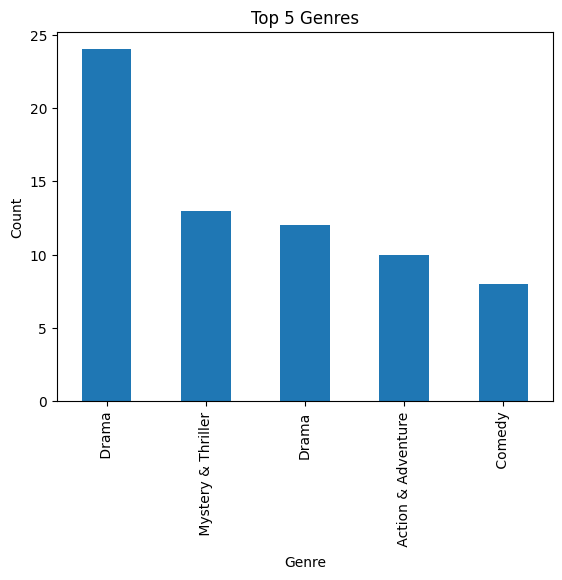

In [ ]:
import matplotlib.pyplot as plt

# Assuming your DataFrame is named df_filtered_tv
# Replace 'Genre' with the actual column name containing genre information

# Convert the 'Genre' column to strings
df_filtered_tv['Genre'] = df_filtered_tv['Genre'].astype(str)

# Split genres if they are stored as a comma-separated string
df_filtered_tv['Genre'] = df_filtered_tv['Genre'].str.split(',')

# Use explode to transform the comma-separated genre strings into separate rows
df_exploded = df_filtered_tv.explode('Genre')

# Count occurrences of each genre
top_genres = df_exploded['Genre'].value_counts()

# Get the top 5 genres
top_genres_top5 = top_genres.head(5)

# Display the top 5 genres
print("Top 5 Genres:")
print(top_genres_top5)

top_genres_top5.plot(kind='bar', xlabel='Genre', ylabel='Count', title='Top 5 Genres')
plt.show()


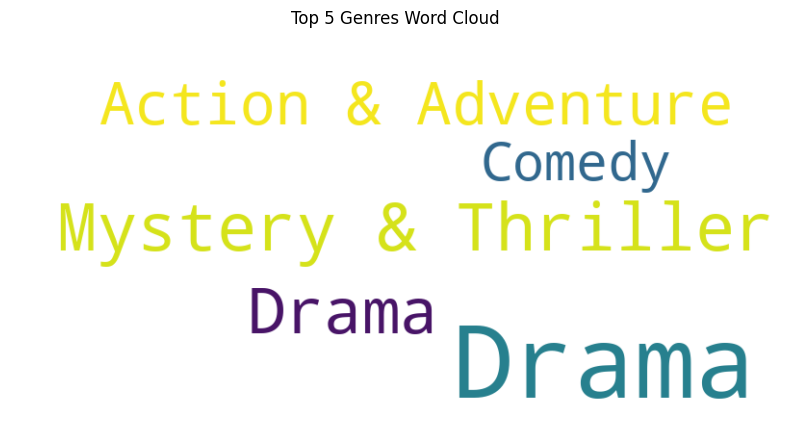

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Assuming top_genres_top5 is the DataFrame containing the top 5 genres
# If not, replace it with the correct DataFrame

# Convert the top_genres_top5 Series to a dictionary
wordcloud_data = top_genres_top5.to_dict()

# Generate the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(wordcloud_data)

# Display the word cloud using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Top 5 Genres Word Cloud')
plt.show()

Top 5 Genres:
 Drama                 24
 Mystery & Thriller    13
Drama                  12
 Action & Adventure    10
 Comedy                 8
Name: Genre, dtype: int64


<ipython-input-354-b0deb81c736e>:7: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_movie['Genre'] = df_filtered_movie['Genre'].astype(str)
<ipython-input-354-b0deb81c736e>:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered_movie['Genre'] = df_filtered_movie['Genre'].str.split(',')


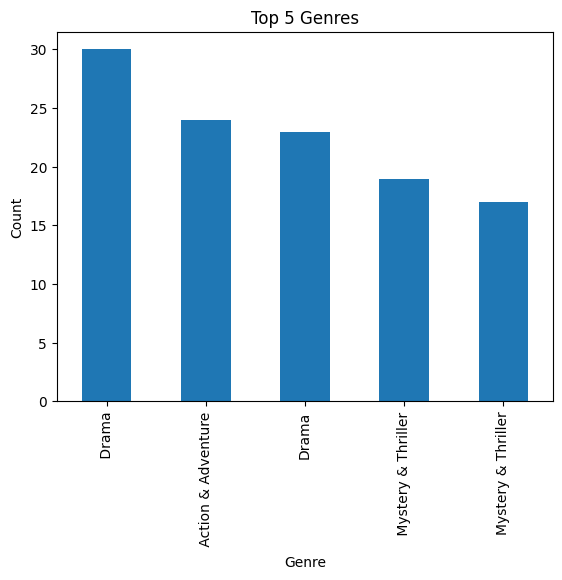

In [ ]:
import matplotlib.pyplot as plt

# Assuming your DataFrame is named df_filtered_movie
# Replace 'Genre' with the actual column name containing genre information

# Convert the 'Genre' column to strings
df_filtered_movie['Genre'] = df_filtered_movie['Genre'].astype(str)

# Split genres if they are stored as a comma-separated string
df_filtered_movie['Genre'] = df_filtered_movie['Genre'].str.split(',')

# Use explode to transform the comma-separated genre strings into separate rows
df_exploded = df_filtered_movie.explode('Genre')

# Count occurrences of each genre
top_genres = df_exploded['Genre'].value_counts()

# Get the top 5 genres
top_genres_top5_mo= top_genres.head(5)

# Display the top 5 genres
print("Top 5 Genres:")
print(top_genres_top5)

top_genres_top5_mo.plot(kind='bar', xlabel='Genre', ylabel='Count', title='Top 5 Genres')
plt.show()

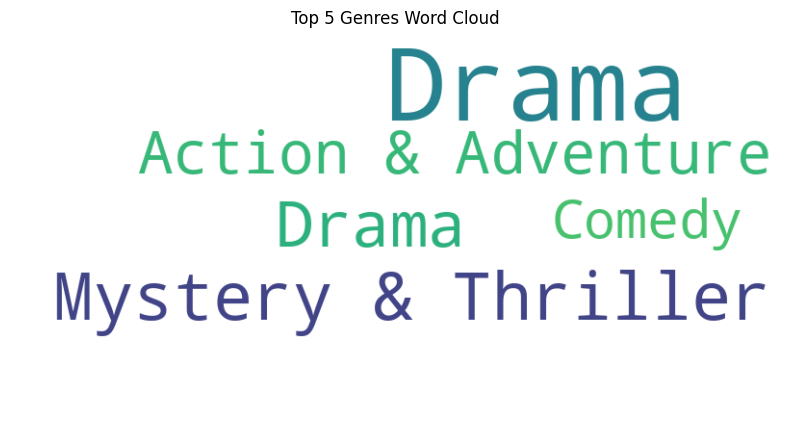

In [ ]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Assuming top_genres_top5 is the DataFrame containing the top 5 genres
# If not, replace it with the correct DataFrame

# Convert the top_genres_top5 Series to a dictionary
wordcloud_data_movie= top_genres_top5.to_dict()

# Generate the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(wordcloud_data_movie)

# Display the word cloud using matplotlib
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Top 5 Genres Word Cloud')
plt.show()

## **Finding Predominant Streaming Service**

Top Streaming Services:
Netflix               15
Hotstar                7
Amazon Prime Video     7
NaN                    2
Amazon miniTV          2
Apple TV Plus          1
Jio Cinema             1
Crunchyroll            1
Sony Liv               1
Lionsgate Play         1
Name: Streaming services, dtype: int64


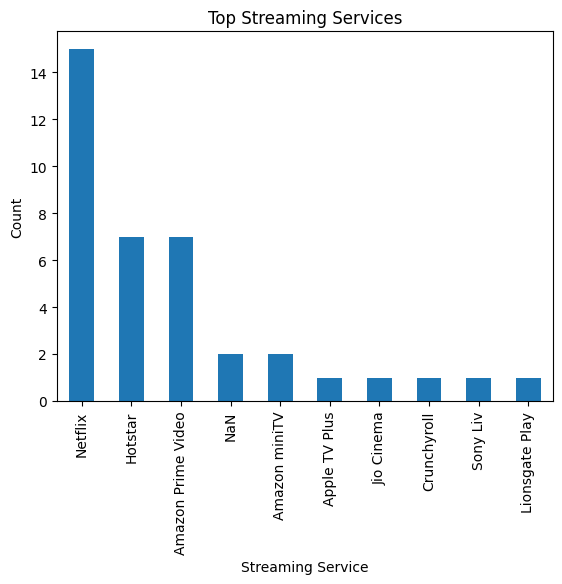

In [ ]:
# Write Your Code here
top_streaming_services = df_filtered_tv['Streaming services'].value_counts()

# Display the top streaming services
print("Top Streaming Services:")
print(top_streaming_services)

# Plot the top streaming services
top_streaming_services.plot(kind='bar', xlabel='Streaming Service', ylabel='Count', title='Top Streaming Services')
plt.show()

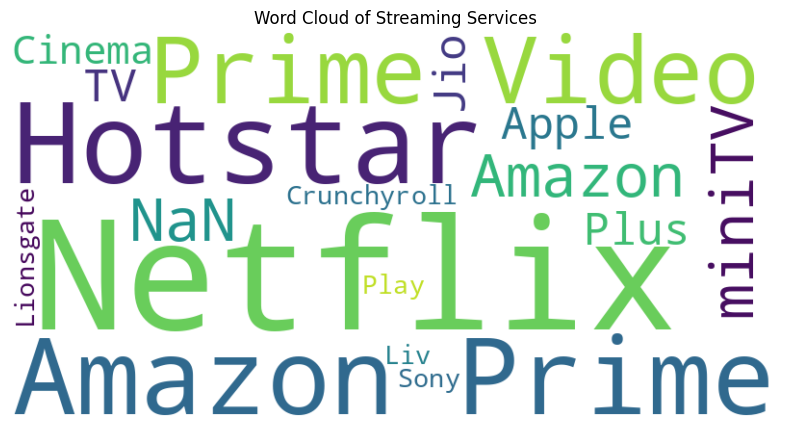

In [ ]:
#Let's Visvalize it using word cloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Assuming your DataFrame is named df
# Replace 'Streaming services' with the actual column name containing streaming service information

# Concatenate all streaming services into a single string
all_services_text = ' '.join(df_filtered_tv['Streaming services'].dropna())

# Generate the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_services_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Streaming Services')
plt.show()

Top Streaming Services:
Amazon Prime Video    17
Netflix               15
Apple TV              12
NaN                   11
Bookmyshow             9
Hotstar                6
Zee5                   3
Apple TV Plus          2
Lionsgate Play         2
Sony Liv               1
aha                    1
Amazon Video           1
Name: Streaming services, dtype: int64


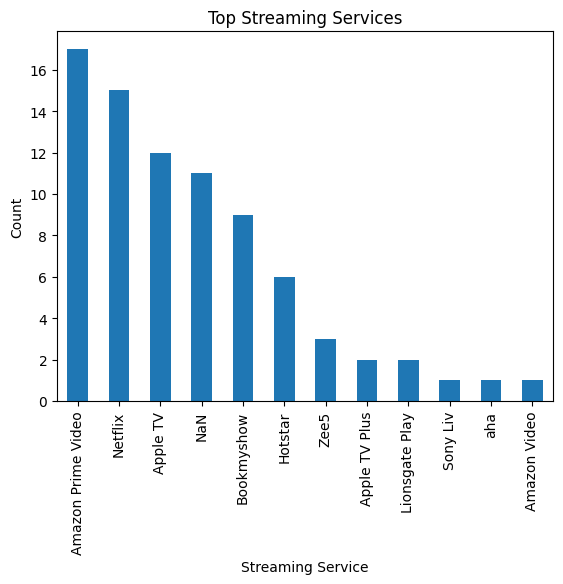

In [ ]:
# Write Your Code here
top_streaming_services = df_filtered_movie['Streaming services'].value_counts()

# Display the top streaming services of movie
print("Top Streaming Services:")
print(top_streaming_services)

# Plot the top streaming services
top_streaming_services.plot(kind='bar', xlabel='Streaming Service', ylabel='Count', title='Top Streaming Services')
plt.show()

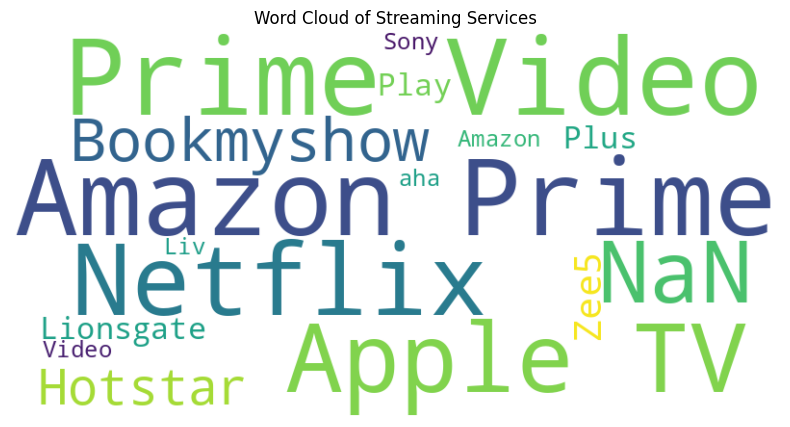

In [ ]:
#Let's Visvalize it using word cloud
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# Assuming your DataFrame is named df
# Replace 'Streaming services' with the actual column name containing streaming service information

# Concatenate all streaming services into a single string
all_services_text = ' '.join(df_filtered_movie['Streaming services'].dropna())

# Generate the word cloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate(all_services_text)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud of Streaming Services')
plt.show()

## **Task 3 :- Data Export**

In [ ]:
#saving final dataframe as Final Data in csv format
df_movie.to_csv('movie_data.csv')
df_tv.to_csv('tv data.csv')

In [ ]:
#saving filter data as Filter Data in csv format
df_filtered_movie.to_csv('filterd movie data.csv')
df_filtered_tv.to_csv('tv filterd data.csv')

# **Dataset Drive Link (View Access with Anyone) -**

# ***Congratulations!!! You have completed your Assignment.***